# CA3 Capstone Project - Predicting Food Waste with Machine Learning
Dataset: Food Waste Recycling Impact - Town of Cary
https://data.townofcary.org/explore/dataset/food-waste-pilot/

In [3]:
# I used this code to import the libraries I need for data analysis and charts
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [4]:
# I used this code to load the dataset and see the first 5 rows
df = pd.read_csv('food-waste-pilot.csv')
df.head()

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
0,Citizen's Convenience Center,2026-04-29,515.8,52.0
1,Mills Park,2026-04-29,537.0,54.0
2,Mills Park,2026-04-27,561.0,56.0
3,Citizen's Convenience Center,2026-04-27,1093.0,109.0
4,Citizen's Convenience Center,2026-04-24,641.6,64.0


In [5]:
# I used this code to check the size of the dataset (rows, columns)
df.shape

(1006, 4)

i saw, the dataset has 1006 rows and 4 columns.

In [6]:
# I used this code to check the data type of each column and see if there are empty values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1006 entries, 0 to 1005
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Stop Name                         1006 non-null   str    
 1   Collection Date                   1006 non-null   str    
 2   Food Waste Collected              1006 non-null   float64
 3   Estimated Earned Compost Created  1006 non-null   float64
dtypes: float64(2), str(2)
memory usage: 62.7 KB


In [7]:
# I used this code to see the main statistics of the numeric columns
df.describe()

,Food Waste Collected,Estimated Earned Compost Created
count,1006.000000,1006.000000
mean,644.130219,64.382704
std,307.244105,30.726067
min,0.000000,0.000000
25%,452.900000,45.000000
50%,598.400000,60.000000
75%,762.975000,76.000000
max,2057.000000,206.000000


i can see, the average food waste per collection is about 644 lbs. The minimum is 0 lbs, which may mean the site was closed that day, and the maximum is about 2,057 lbs, which may be an outlier.

In [8]:
# I used this code to see how many collections each drop-off site has
df['Stop Name'].value_counts()

Stop Name
Citizen's Convenience Center    656
Mills Park                      350
Name: count, dtype: int64

As we can see, there are 2 sites: Citizen's Convenience Center (656 collections) and Mills Park (350 collections). Our target is Food Waste Collected.

In [9]:
# I used this code to check if there are missing values in each column
df.isnull().sum()

Stop Name                           0
Collection Date                     0
Food Waste Collected                0
Estimated Earned Compost Created    0
dtype: int64

So, there are no missing values in the dataset.

In [11]:
# I used this code to convert the Collection Date from text to a real date,
# so I can sort the data by time and create date features later
df['Collection Date'] = pd.to_datetime(df['Collection Date'])
df['Collection Date'].min(), df['Collection Date'].max()

(Timestamp('2022-02-02 00:00:00'), Timestamp('2026-04-29 00:00:00'))

i saw, the data covers more than 4 years, from February 2022 to April 2026.

In [12]:
# I used this code to find duplicated collections
df[df.duplicated(['Stop Name', 'Collection Date'], keep=False)]

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
463,Citizen's Convenience Center,2024-11-01,867.0,87.0
464,Citizen's Convenience Center,2024-11-01,481.8,48.0


In [13]:
# I used this code to add the two pickups together, so each site has only one row per day
df = df.groupby(['Stop Name', 'Collection Date'], as_index=False)[['Food Waste Collected', 'Estimated Earned Compost Created']].sum()
df.shape

(1005, 4)

i see, the dataset now has 1005 rows.

In [14]:
# I used this code to find the collections with 0 lbs of food waste
df[df['Food Waste Collected'] == 0]

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
0,Citizen's Convenience Center,2022-02-02,0.0,0.0
90,Citizen's Convenience Center,2022-09-05,0.0,0.0
119,Citizen's Convenience Center,2022-11-11,0.0,0.0
147,Citizen's Convenience Center,2023-01-16,0.0,0.0
209,Citizen's Convenience Center,2023-06-19,0.0,0.0
298,Citizen's Convenience Center,2024-01-15,0.0,0.0
364,Citizen's Convenience Center,2024-06-19,0.0,0.0
456,Citizen's Convenience Center,2025-01-20,0.0,0.0
457,Citizen's Convenience Center,2025-01-22,0.0,0.0
493,Citizen's Convenience Center,2025-04-17,0.0,0.0


from this table i see, there are 15 collections with 0 lbs. These dates are public holidays In the USA (for example Labor Day and Juneteenth), so the site was closed. A 0 here does not mean "no food waste", so I will remove these rows.

In [15]:
# I used this code to remove the days when the site was closed
df = df[df['Food Waste Collected'] > 0]
df.shape

(990, 4)

In [16]:
# I used this code to check the first collections at Mills Park
df[df['Stop Name'] == 'Mills Park'].sort_values('Collection Date').head()

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
655,Mills Park,2022-08-25,664.8,66.0
657,Mills Park,2024-02-02,66.4,7.0
658,Mills Park,2024-02-05,171.8,17.0
659,Mills Park,2024-02-07,207.0,21.0
660,Mills Park,2024-02-09,181.4,18.0


i saw there is one Mills Park collection in August 2022, and then nothing Until January 2024. Mills Park opened in 2024, so this row is probably a data entry error.

In [17]:
# I used this code to remove the wrong Mills Park row from 2022
df = df[~((df['Stop Name'] == 'Mills Park') & (df['Collection Date'] < '2024-01-01'))]
df.shape

(989, 4)

In [18]:
# I used this code to check the correlation between the food waste and the compost created
df[['Food Waste Collected', 'Estimated Earned Compost Created']].corr()

,Food Waste Collected,Estimated Earned Compost Created
Food Waste Collected,1.000000,0.999952
Estimated Earned Compost Created,0.999952,1.000000


In [19]:
# I used this code to remove the compost column to avoid data leakage
df = df.drop('Estimated Earned Compost Created', axis=1)
df.head()

,Stop Name,Collection Date,Food Waste Collected
1,Citizen's Convenience Center,2022-02-09,59.0
2,Citizen's Convenience Center,2022-02-11,197.0
3,Citizen's Convenience Center,2022-02-14,329.4
4,Citizen's Convenience Center,2022-02-16,102.8
5,Citizen's Convenience Center,2022-02-18,202.8


i see, the dataset now has only 3 columns: Stop Name, Collection Date and Food Waste Collected.

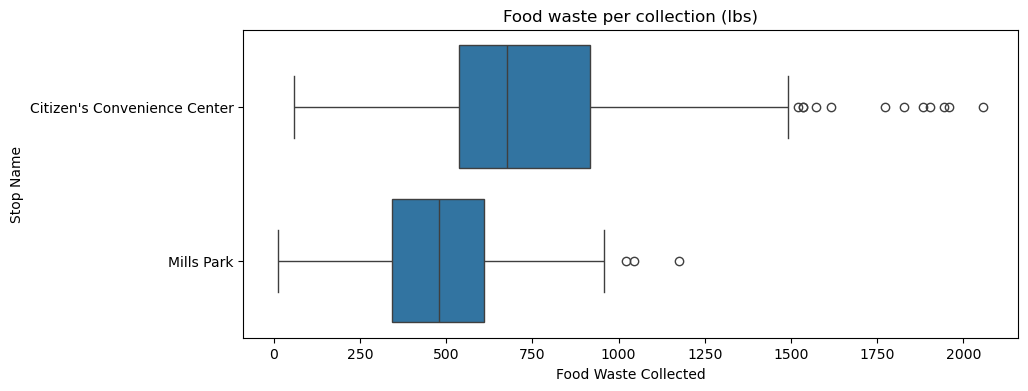

In [20]:
# I used this code to look for outliers in the food waste for each site
plt.figure(figsize=(10, 4))
sns.boxplot(x='Food Waste Collected', y='Stop Name', data=df)
plt.title('Food waste per collection (lbs)')
plt.show()

In [21]:
# I used this code to count the outliers with the IQR method and see on which days they happen
Q1 = df['Food Waste Collected'].quantile(0.25)
Q3 = df['Food Waste Collected'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[df['Food Waste Collected'] > Q3 + 1.5 * IQR]
print('Number of outliers:', len(outliers))
outliers['Collection Date'].dt.day_name().value_counts()

Number of outliers: 55


Collection Date
Monday       44
Wednesday     5
Tuesday       3
Friday        3
Name: count, dtype: int64